In [1]:
from photutils.segmentation import SourceCatalog, deblend_sources, detect_sources, detect_threshold
from astropy.io import fits
from matplotlib import pyplot as plt
import numpy as np
from astropy.visualization import ZScaleInterval
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from astropy.table import Table

In [2]:
#Abrimos los datos de los fits
img_b = fits.open('Img_B.fits')[0].data
img_v = fits.open('Img_V.fits')[0].data
hdr_b = fits.open('Img_B.fits')[0].header
hdr_v = fits.open('Img_V.fits')[0].header
hdr_b

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 4096                                                  
NAXIS2  =                 4096                                                  
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
OBSERVER= 'Cortes, Martinez, Soto' / SBIGFITSEXT The name of the observer       
ORIGIN  = 'MAS500  '           / Description of location                        
TELESCOP= 'MAS500  '           / SBIGFITSEXT The model Telescope                
FOCALLEN=                6500. / SBIGFITSEXT Telescope focal length in mm       
APTDIA  =                 500. / SBIGFITSEXT Aperture diameter in mm            
SBUUID  = '{fac0fa44-d970-46

In [3]:
# Threshold para detectar fuentes
threshold_b = detect_threshold(img_b, n_sigma=3)
threshold_v = detect_threshold(img_v, n_sigma=3)

# Detectamos fuentes
sour_b = detect_sources(img_b, threshold_b, n_pixels=5)
sour_v = detect_sources(img_v, threshold_v, n_pixels=5)

print(sour_b)
print(sour_v)

<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 4573
labels: [   1    2    3    4    5 ... 4569 4570 4571 4572 4573]
<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 4534
labels: [   1    2    3    4    5 ... 4530 4531 4532 4533 4534]


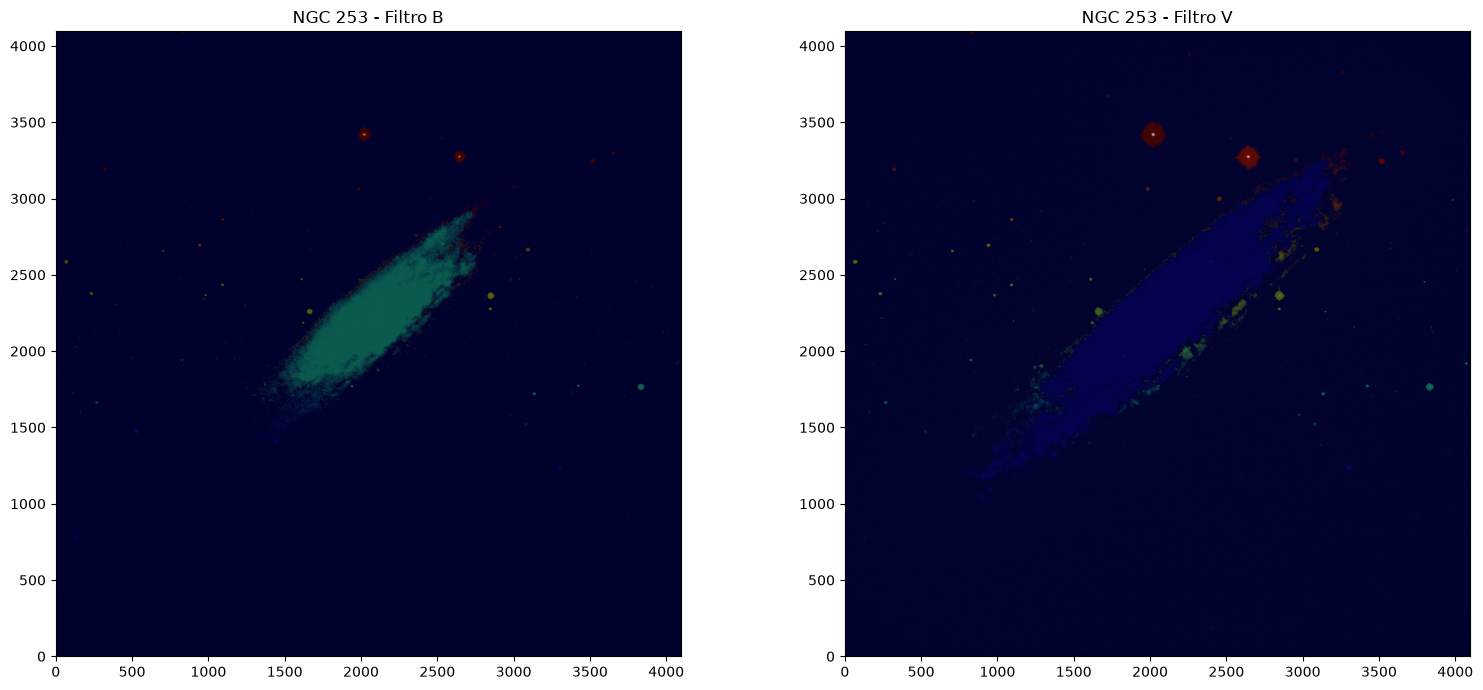

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7))

# Filtro B
ax[0].imshow(img_b, cmap='gray', origin='lower')
if sour_b is not None:
    ax[0].imshow(sour_b.data, cmap='jet', origin='lower', alpha=0.35)
ax[0].set_title('NGC 253 - Filtro B')

# Filtro V
ax[1].imshow(img_v, cmap='gray', origin='lower')
if sour_v is not None:
    ax[1].imshow(sour_v.data, cmap='jet', origin='lower', alpha=0.35)
ax[1].set_title('NGC 253 - Filtro V')

plt.tight_layout()
plt.show()

In [5]:
#Separamos fuentes
deblend_b = deblend_sources(img_b, sour_b, npixels=10, nlevels=32, contrast=0.05)
deblend_v = deblend_sources(img_v, sour_v, npixels=10, nlevels=32, contrast=0.05)
#npixels tamaño mínimo para considerar una subregión significativa.
#contrast evita dividir la nebulosa en demasiados trozos.
#nlevels uficiente resolución sin fragmentar el gas difuso.
print(deblend_b, deblend_v)

<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 4792
labels: [   1    2    3    4    5 ... 4788 4789 4790 4791 4792] <photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 4816
labels: [   1    2    3    4    5 ... 4812 4813 4814 4815 4816]


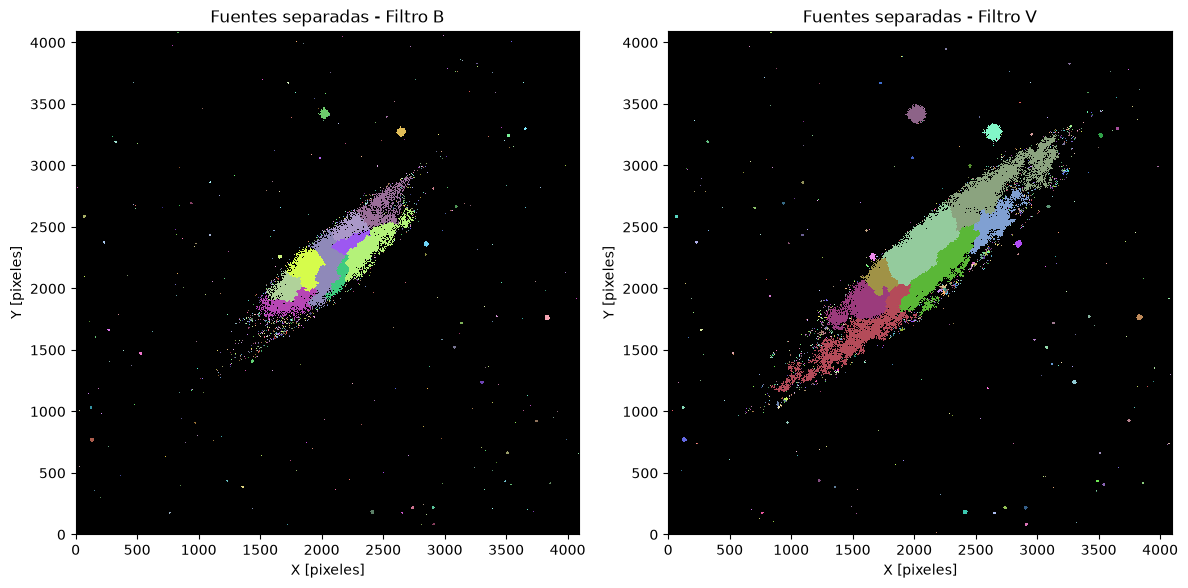

In [6]:
# Creamos los mapas de colores
cmap_deblend_b = deblend_b.make_cmap(seed=123)
cmap_deblend_v = deblend_v.make_cmap(seed=123)

# Visualizamos las fuentes separadas
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Filtro B
ax[0].imshow(
    deblend_b.data,
    origin='lower',
    cmap=cmap_deblend_b,
    interpolation='nearest'
)
ax[0].set_title('Fuentes separadas - Filtro B')
ax[0].set_xlabel('X [pixeles]')
ax[0].set_ylabel('Y [pixeles]')

# Filtro V
ax[1].imshow(
    deblend_v.data,
    origin='lower',
    cmap=cmap_deblend_v,
    interpolation='nearest'
)
ax[1].set_title('Fuentes separadas - Filtro V')
ax[1].set_xlabel('X [pixeles]')
ax[1].set_ylabel('Y [pixeles]')

plt.tight_layout()
plt.show()

In [7]:
#Catalogo
cat_b = SourceCatalog(img_b, deblend_b)
cat_v = SourceCatalog(img_v, deblend_v)
tbl_b = cat_b.to_table()
tbl_v = cat_b.to_table()
print(tbl_b)
print(tbl_v)

label     x_centroid     ... kron_flux_err flags 
                         ...                     
----- ------------------ ... ------------- ------
    1 1464.0087865604596 ...           nan   8192
    2 2358.4932943632434 ...           nan      0
    3  1792.712862223117 ...           nan      0
    4  3033.158046794066 ...           nan      0
    5 3655.1513015367354 ...           nan      0
    6  853.1573215629048 ...           nan      0
  ...                ... ...           ...    ...
 4786 2806.5304387069286 ...           nan 393248
 4787 2813.0802416543447 ...           nan 393248
 4788 2457.2418437877577 ...           nan 131104
 4789   2450.49470986877 ...           nan 131104
 4790  2454.171507230249 ...           nan 131104
 4791 3001.0230374261205 ...           nan 393248
 4792 3011.0154735352903 ...           nan 131104
Length = 4792 rows
label     x_centroid     ... kron_flux_err flags 
                         ...                     
----- ------------------ ... --

In [8]:
#Tablas
tabla_b = cat_b.to_table()['label','xcentroid','ycentroid','area','segment_flux']
tabla_v = cat_v.to_table()['label','xcentroid','ycentroid','area','segment_flux']

#Printeo las tablas con los datos
print(tabla_b, tabla_v)

label     x_centroid     ...    segment_flux   
                         ...                   
----- ------------------ ... ------------------
    1 1464.0087865604596 ... 333.09395599365234
    2 2358.4932943632434 ... 1523.7975463867188
    3  1792.712862223117 ...  409.0527801513672
    4  3033.158046794066 ...  359.2322235107422
    5 3655.1513015367354 ... 478.58562088012695
    6  853.1573215629048 ...  422.4443550109863
  ...                ... ...                ...
 4786 2806.5304387069286 ...   1421.54052734375
 4787 2813.0802416543447 ... 1401.3523483276367
 4788 2457.2418437877577 ... 1263.8486709594727
 4789   2450.49470986877 ... 1840.0074729919434
 4790  2454.171507230249 ... 2237.5320358276367
 4791 3001.0230374261205 ...  2963.263027191162
 4792 3011.0154735352903 ...  3809.636417388916
Length = 4792 rows label     x_centroid     ...    segment_flux   
                         ...                   
----- ------------------ ... ------------------
    1  2178.839430330

In [9]:
#Flujo real
tabla_b['segment_flux'] = tabla_b['segment_flux']/hdr_b['EXPTIME']
tabla_v['segment_flux'] = tabla_v['segment_flux']/hdr_v['EXPTIME']

print(tabla_b, tabla_v)

label     x_centroid     ...    segment_flux   
                         ...                   
----- ------------------ ... ------------------
    1 1464.0087865604596 ... 1.3878914833068847
    2 2358.4932943632434 ... 6.3491564432779946
    3  1792.712862223117 ...   1.70438658396403
    4  3033.158046794066 ... 1.4968009312947592
    5 3655.1513015367354 ... 1.9941067536671957
    6  853.1573215629048 ... 1.7601848125457764
  ...                ... ...                ...
 4786 2806.5304387069286 ...  5.923085530598958
 4787 2813.0802416543447 ...  5.838968118031819
 4788 2457.2418437877577 ...  5.266036128997802
 4789   2450.49470986877 ...  7.666697804133097
 4790  2454.171507230249 ...   9.32305014928182
 4791 3001.0230374261205 ... 12.346929279963176
 4792 3011.0154735352903 ... 15.873485072453816
Length = 4792 rows label     x_centroid     ...    segment_flux   
                         ...                   
----- ------------------ ... ------------------
    1  2178.839430330

In [10]:
#Magnitudes con los zeropoint de la calibracion
zp_b = 39.26419337
zp_v = 39.65931555
tabla_b['magnitude'] = zp_b - 2.5 * np.log(tabla_b['segment_flux'])
tabla_v['magnitude'] = zp_v - 2.5 * np.log(tabla_v['segment_flux'])
print(tabla_b, tabla_v)

label     x_centroid     ...     magnitude     
                         ...                   
----- ------------------ ... ------------------
    1 1464.0087865604596 ... 38.444729177568306
    2 2358.4932943632434 ...   34.6433884687454
    3  1792.712862223117 ...  37.93118019200039
    4  3033.158046794066 ... 38.255868074579844
    5 3655.1513015367354 ...  37.53870285111874
    6  853.1573215629048 ...   37.8506463433363
  ...                ... ...                ...
 4786 2806.5304387069286 ...  34.81704957597726
 4787 2813.0802416543447 ...  34.85280814722399
 4788 2457.2418437877577 ... 35.110998565361676
 4789   2450.49470986877 ... 34.171978398346354
 4790  2454.171507230249 ... 33.682968759017875
 4791 3001.0230374261205 ... 32.980674892852285
 4792 3011.0154735352903 ...   32.3525680907042
Length = 4792 rows label     x_centroid     ...     magnitude     
                         ...                   
----- ------------------ ... ------------------
    1  2178.839430330

In [11]:
print(f"{np.sort(tabla_b['magnitude'])}")
print(f"{np.sort(tabla_v['magnitude'])}")

    magnitude     
------------------
13.817438890088752
14.237219840794026
14.272782504177176
14.940436405439144
15.144391154672899
15.557960664277704
15.775811493989835
               ...
  39.5344912368302
 39.53598028993169
 39.53719085714702
  39.5388663681142
39.539440603446934
 39.55467632987669
 39.55771568391446
Length = 4792 rows
    magnitude     
------------------
11.156097213767648
11.202786653135238
 11.73797301028609
11.934830810698315
12.355610438655365
12.428153433791348
13.929213164436938
               ...
39.379347185570474
 39.38119468160239
39.383972082932345
39.384220885909045
39.385974064746634
39.386787777909646
39.386986044831644
Length = 4816 rows


In [39]:
# Limitar a 250 fuentes para facilitar la visualización del diagrama color-magnitud
n = min(len(tabla_v), len(tabla_b), 250)
B_V = tabla_b['magnitude'][:n] - tabla_v['magnitude'][:n]

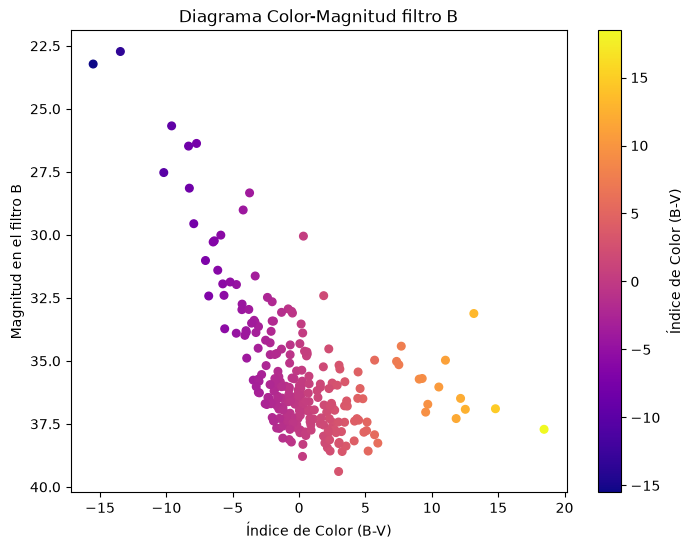

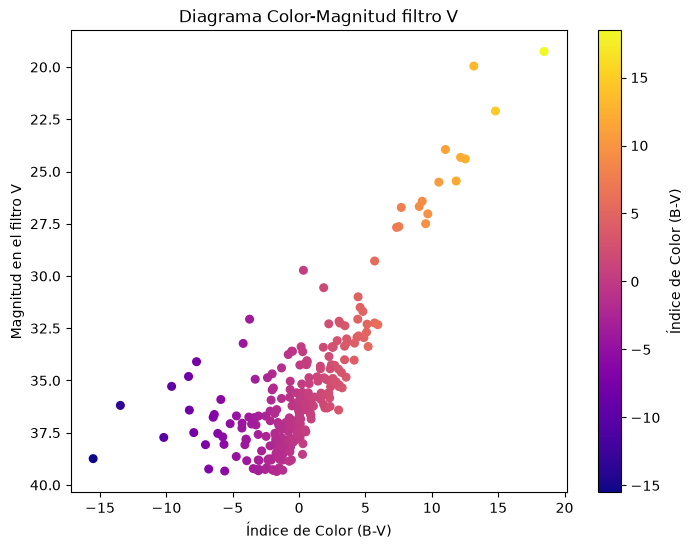

In [40]:
# Crear el diagrama color-magnitud
plt.figure(figsize=(8, 6))
plt.scatter(B_V, tabla_b['magnitude'][:n], c=B_V, cmap='plasma', s = 30)
plt.colorbar(label="Índice de Color (B-V)")
plt.gca().invert_yaxis()  # Invertir el eje y para que las magnitudes más brillantes estén arriba

# Añadir etiquetas
plt.xlabel("Índice de Color (B-V)")
plt.ylabel("Magnitud en el filtro B")
plt.title("Diagrama Color-Magnitud filtro B")

plt.show()

# Crear el diagrama color-magnitud
plt.figure(figsize=(8, 6))
plt.scatter(B_V, tabla_v['magnitude'][:n], c=B_V, cmap='plasma', s = 30)
plt.colorbar(label="Índice de Color (B-V)")
plt.gca().invert_yaxis()  # Invertir el eje y para que las magnitudes más brillantes estén arriba

# Añadir etiquetas
plt.xlabel("Índice de Color (B-V)")
plt.ylabel("Magnitud en el filtro V")
plt.title("Diagrama Color-Magnitud filtro V")

plt.show()